In [8]:
%matplotlib inline

import math
import time
import torch
import random
import numpy as np
from d2l import torch as d2l
from matplotlib_inline.backend_inline import set_matplotlib_formats

def use_svg_display():
    set_matplotlib_formats('svg')

d2l.use_svg_display = use_svg_display

In [9]:
n = 1000
a = torch.ones([n])
b = torch.ones([n])

In [ ]:
class Timer: #@save
    "记录多次运行时间"
    def __init__(self):
        self.times = []
        self.start()

    def start(self):
        "启动计时器"
        self.tik = time.time()

    def stop(self):
        "停止计时器并将时间记录在列表中"
        self.times.append(time.time() - self.tik)
        return self.times[-1]

    def avg(self):
        "返回平均时间"
        return sum(self.times) / len(self.times)

    def sum(self):
        "返回时间总和"
        return sum(self.times)

    def cumsum(self):
        "返回累计时间"
        return np.array(self.times).cumsum().tolist()

In [11]:
c = torch.zeros(n)
timer = Timer()
for i in range(n):
        c[i] = a[i] + b[i]

f'{timer.stop():.5f} sec'

'0.01048 sec'

In [12]:
# 这里进行矢量化运算，相同的内容，下面会比上面快很多
timer.start()
d = a + b
f'{timer.stop():.5f} sec'

'0.00012 sec'

In [13]:
# 正态分布
def normal(x, mu, sigma):
    p = 1 / math.sqrt(2 * math.pi * sigma**2)
    return p * np.exp(-0.5 / sigma**2 * (x-mu)**2)

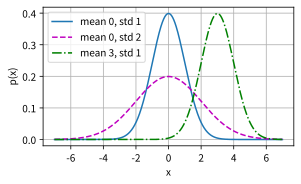

In [14]:
x = np.arange(-7, 7, 0.01)

params = [(0, 1), (0, 2), (3, 1)]
d2l.plot(x, [normal(x, mu, sigma) for mu, sigma in params], xlabel='x',
         ylabel='p(x)', figsize=(4.5, 2.5),
         legend=[f'mean {mu}, std {sigma}' for mu, sigma in params])

# 实现 Linear Regression

In [15]:
def synthetic_data(w, b, num_examples):  #@save
    """生成 y=Xw+b+噪声"""
    # pytorch 的 normal 返回的是高斯分布采样的结果，传入的是 mu, sigma, shape
    X = torch.normal(0, 1, (num_examples, len(w)))
    y = torch.matmul(X, w) + b
    y += torch.normal(0, 0.01, y.shape)
    return X, y.reshape((-1, 1))

In [16]:
true_w = torch.tensor([2, -3.4])
true_b = 4.2
features, labels = synthetic_data(true_w, true_b, 1000)
print('features:', features[0],'\nlabel:', labels[0])

features: tensor([-0.2202, -0.2354]) 
label: tensor([4.5580])


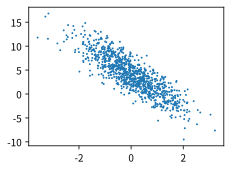

In [19]:
d2l.set_figsize()
d2l.plt.scatter(features[:,1].detach().numpy(), labels.detach().numpy(), 1)

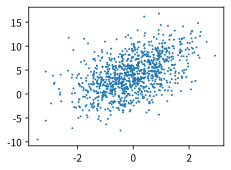

In [20]:
d2l.set_figsize()
d2l.plt.scatter(features[:, 0].detach().numpy(), labels.detach().numpy(), 1)

In [23]:
def data_iter(batch_size, features, labels):
    num_examples = len(features)
    indices = list(range(num_examples))
    random.shuffle(indices)
    for i in range(0, num_examples, batch_size):
        batch_indices = torch.tensor(indices[i:min(i+batch_size, num_examples)])
        yield features[batch_indices], labels[batch_indices]

In [24]:
batch_size = 10

for X, y in data_iter(batch_size, features, labels):
    print(X, '\n', y)
    break

tensor([[-0.1062,  0.7396],
        [ 0.0200,  0.6480],
        [-0.3033, -0.2442],
        [ 1.1156, -0.8985],
        [-0.2515,  0.9426],
        [-0.1950, -0.2735],
        [-0.3369,  1.4988],
        [ 1.2425, -2.2152],
        [ 1.4996,  0.9999],
        [ 0.4292,  0.2319]]) 
 tensor([[ 1.4874],
        [ 2.0291],
        [ 4.4186],
        [ 9.4984],
        [ 0.4824],
        [ 4.7350],
        [-1.5717],
        [14.1978],
        [ 3.8005],
        [ 4.2544]])


In [25]:
w = torch.normal(0, 0.01, size=(2,1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)

In [28]:
# 定义模型，这样理解的话，模型其实就是一个函数/神经网络
def linreg(X, w, b): #@save
    """线性回归模型"""
    return torch.matmul(X, w) + b

def squared_loss(y_hat, y): #@save
    """均方损失"""
    return (y_hat - y.reshape(y_hat.shape)) ** 2 / 2

def sgd(params, lr, batch_size): #@save
    """小批量随即梯度下降"""
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad / batch_size
            param.grad.zero_()

In [29]:
# 训练
lr = 0.03
num_epochs = 3
net = linreg
loss = squared_loss

for epoch in range(num_epochs):
    for X, y in data_iter(batch_size, features, labels):
        l = loss(net(X, w, b), y)
        
        l.sum().backward()
        sgd([w, b], lr, batch_size)
    
    with torch.no_grad():
        train_l = loss(net(features, w, b), labels)
        print(f'epoch {epoch + 1}, loss {float(train_l.mean()):f}')

epoch 1, loss 0.047916
epoch 2, loss 0.000196
epoch 3, loss 0.000055
